In [33]:
import torch
from scripts.model import EmbeddingNet
from scripts.data import load_lfw, make_splits, TripletDataset, IMG_SIZE, to_pil_image, get_transforms
import numpy as np
from PIL import Image
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

In [2]:
MODELS_DIR = "./models"

In [3]:
def load_checkpoint(model_type, num_classes, device):
    ckpt = torch.load(MODELS_DIR + "/" +  f"{model_type}.pt", map_location=device,
                      weights_only=False)
    model = EmbeddingNet().to(device)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model, ckpt

In [11]:
class FaceDataset(Dataset):
    def __init__(self, images, labels, train: bool):
        self.images = images
        self.labels = labels
        self.transform = get_transforms(train)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        img = self.transform(Image.fromarray(self.images[i]))
        return img, int(self.labels[i])

In [13]:
@torch.no_grad()
def embed(model, images, labels, device):
    ds = FaceDataset(images, labels, train=False)
    loader = DataLoader(ds, batch_size=64)
    out = [model(x.to(device)).cpu() for x, _ in loader]
    return torch.cat(out).numpy()

In [4]:
images, labels, class_names = load_lfw()

In [16]:
train_idx, val_idx, test_idx = make_splits(labels)

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [7]:
model, _ = load_checkpoint("triplet", len(class_names), device)

In [8]:
sum(p.numel() for p in model.parameters())

11242176

In [14]:
emb_train = embed(model, images[train_idx], labels[train_idx], device)

In [17]:
emb_test = embed(model, images[test_idx], labels[test_idx], device)

In [19]:
emb_train.shape, emb_test.shape

((2116, 128), (454, 128))

In [20]:
y_train, y_test = labels[train_idx], labels[test_idx]

### KNN

In [23]:
knn = KNeighborsClassifier(n_neighbors=5, metric="cosine")
knn.fit(emb_train, y_train)
knn_acc = knn.score(emb_test, y_test)

In [24]:
knn_acc

0.7312775330396476

### ROC - AUC Score

In [29]:
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score,
                             roc_curve)

In [25]:
SEED = 42

In [48]:
by_class = {c: np.where(y_test == c)[0] for c in np.unique(y_test)}
multi = [c for c, idxs in by_class.items() if len(idxs) > 1]

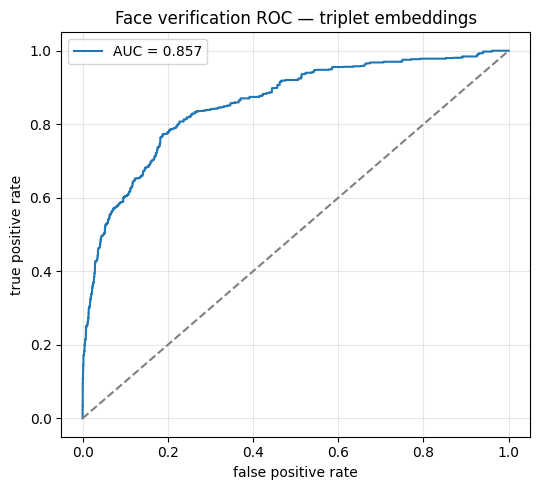

In [73]:
rng = np.random.default_rng(SEED)
sims, targets = [], []

for _ in range(3000):
    c = rng.choice(multi)
    i, j = rng.choice(by_class[c], 2, replace=False)
    sim_pos = float(emb_test[i] @ emb_test[j])
    sims.append(sim_pos)
    targets.append(1)
    
    c1, c2 = rng.choice(list(by_class), 2, replace=False)
    i2 = rng.choice(by_class[c1])
    j2 = rng.choice(by_class[c2])
    sim_neg = float(emb_test[i2] @ emb_test[j2])
    sims.append(sim_neg)
    targets.append(0)
    
auc = roc_auc_score(targets, sims)
fpr, tpr, _ = roc_curve(targets, sims)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
plt.title("Face verification ROC — triplet embeddings")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()

### T-SNE

In [74]:
# t-SNE of test embeddings for the 10 most frequent identities.
top10 = np.argsort(np.bincount(y_test))[::-1][:10]

In [75]:
top10

array([14, 10, 58, 12, 15,  5, 21, 35, 31, 25])

In [76]:
class_names[top10[0]]

'George W Bush'

In [77]:
mask = np.isin(y_test, top10)
proj = TSNE(n_components=2, random_state=SEED, perplexity=20).fit_transform(emb_test[mask])

In [79]:
proj.shape

(221, 2)

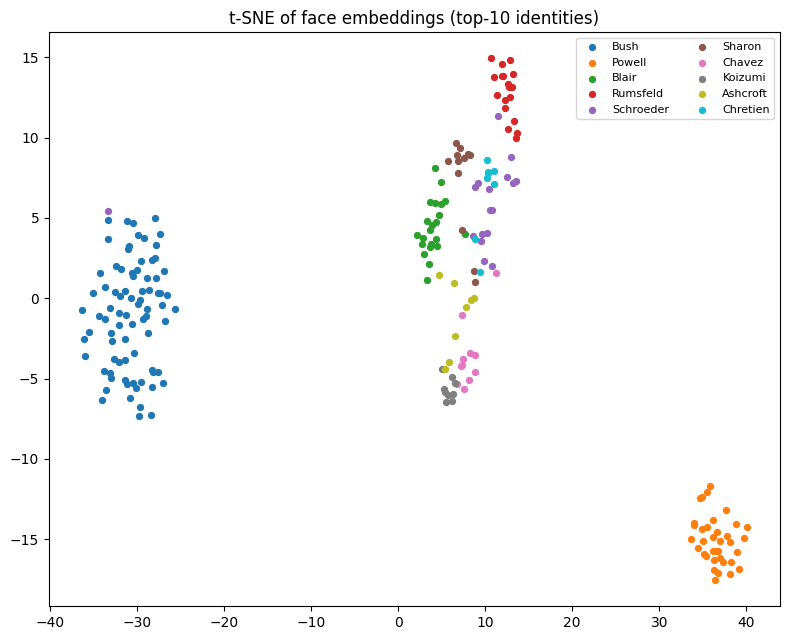

In [80]:
plt.figure(figsize=(8, 6.5))
for c in top10:
    m = y_test[mask] == c
    plt.scatter(proj[m, 0], proj[m, 1], s=18, label=class_names[c].split()[-1])
plt.legend(fontsize=8, ncol=2)
plt.title("t-SNE of face embeddings (top-10 identities)")
plt.tight_layout()